# 05 · TerriData: ¿mejoró la vida de la gente en Acacías?

**Proyecto:** ¿Acacías vive del petróleo? Regalías vs. desarrollo
**Fuente:** DNP, TerriData → Descargas → *Descarga por dimensión* (TXT). Descarga del 24/11/2026.

| Archivo | Dimensión |
|---|---|
| `TerriData_Dim2.txt` | Demografía y población (1 GB) |
| `TerriData_Dim3.txt` | Vivienda y servicios públicos |
| `TerriData_Dim4.txt` | Educación |
| `TerriData_Dim5.txt` | Salud |
| `TerriData_Dim6.txt` | Convivencia y seguridad |
| `TerriData_Dim7.txt` | Finanzas públicas |
| `TerriData_Dim8.txt` | Medición de desempeño municipal |
| `TerriData_Dim12.txt` | Economía |
| `TerriData_Dim14.txt` | Pobreza |

**Comparamos Acacías con:**
- **Meta** (departamento) y **Colombia**, como referencia general.
- **Castilla La Nueva, Guamal y Puerto Gaitán**, otros municipios petroleros del Meta.
- **Villavicencio**, la capital.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.width", 200)

RAW = Path("../data/terridata")
OUT = Path("../data processed")
EXTRACTO = OUT / "terridata_meta_colombia.csv"
ANIO_BASE = 2025

ENTIDADES = {
    "50006": "Acacías",
    "50000": "Meta",
    "01001": "Colombia",
    "50150": "Castilla La Nueva",
    "50318": "Guamal",
    "50568": "Puerto Gaitán",
    "50001": "Villavicencio",
}
COLORES = {"Acacías": "#2a6f97", "Meta": "#e07a5f", "Colombia": "#9aa5b1"}

## 1. Extraer solo Meta y Colombia (se corre una vez)

Los archivos traen **todos los municipios del país** y uno pesa 1 GB, demasiado para abrirlo de una. Se leen **por pedazos** (500.000 filas a la vez) y solo se guardan las filas del Meta (código de departamento `50`) y del total nacional (`01`).

Toma unos minutos. Si el extracto ya existe, se salta este paso.

In [2]:
def extraer(archivos, destino, deptos=("50", "01"), tam=500_000):
    partes = []
    for f in archivos:
        n = 0
        for chunk in pd.read_csv(f, sep="|", dtype=str, encoding="utf-8", chunksize=tam):
            sel = chunk[chunk.iloc[:, 0].isin(deptos)]
            partes.append(sel)
            n += len(sel)
        print(f"{f.name}: {n:,} filas")
    df = pd.concat(partes, ignore_index=True)
    df.to_csv(destino, index=False, encoding="utf-8-sig")
    return df

if EXTRACTO.exists():
    print("El extracto ya existe, se usa directamente:", EXTRACTO.name)
else:
    extraer(sorted(RAW.glob("TerriData_Dim*.txt")), EXTRACTO)

El extracto ya existe, se usa directamente: terridata_meta_colombia.csv


## 2. Limpieza

- Los números vienen en formato colombiano: **punto para miles y coma para decimales** (`1.949.253,00`).
- Algunos indicadores tienen **varias mediciones en el mismo año** (por ejemplo septiembre y diciembre). Se deja **la más reciente** de cada año.
- Algunos indicadores solo traen texto (`Dato Cualitativo`), como el grupo de capacidades del MDM.

In [3]:
td = pd.read_csv(EXTRACTO, dtype=str)
td.columns = ["cod_depto", "depto", "cod_entidad", "entidad", "dimension", "subcategoria", "indicador",
              "dato_num", "dato_cual", "anio", "mes", "fuente", "unidad"]

td["valor"] = pd.to_numeric(
    td["dato_num"].str.replace(".", "", regex=False).str.replace(",", ".", regex=False), errors="coerce")
td["anio"] = td["anio"].astype(int)
td["mes"] = td["mes"].astype(int)

antes = len(td)
td = (td.sort_values("mes")
        .drop_duplicates(["cod_entidad", "dimension", "subcategoria", "indicador", "anio"], keep="last"))
print(f"{antes:,} filas -> {len(td):,} después de quitar mediciones repetidas en el mismo año")
print(td["dimension"].value_counts())

268,253 filas -> 264,517 después de quitar mediciones repetidas en el mismo año
dimension
Demografía y población                    113332
Finanzas públicas                          50528
Economía                                   42301
Salud                                      17176
Educación                                  12322
Convivencia y seguridad ciudadana          12297
Vivienda y acceso a servicios públicos      7303
Medición de desempeño municipal             6635
Pobreza                                     2623
Name: count, dtype: int64


## 3. Indicadores seleccionados

De cientos de indicadores, se eligen los que mejor responden la pregunta del proyecto. `mejor` indica si es bueno que el indicador **suba** o **baje**.

In [4]:
INDICADORES = pd.DataFrame([
    # (indicador en TerriData, nombre corto, tema, mejor)
    ("Cobertura neta en educación - Total", "Cobertura neta educación (%)", "Educación", "sube"),
    ("Tasa de deserción intra-anual del sector oficial en educación básica y media (Desde transición hasta once)", "Deserción escolar oficial (%)", "Educación", "baja"),
    ("Puntaje promedio Pruebas Saber 11 - Matemáticas", "Saber 11 Matemáticas (puntos)", "Educación", "sube"),
    ("Tasa de tránsito inmediato a la educación superior", "Tránsito a educación superior (%)", "Educación", "sube"),
    ("Tasa de mortalidad infantil en menores de 1 año (x cada 1.000 nacidos vivos)", "Mortalidad infantil (x 1.000)", "Salud", "baja"),
    ("Cobertura vacunación pentavalente en menores de 1 año", "Vacunación pentavalente (%)", "Salud", "sube"),
    ("Cobertura de acueducto (REC)", "Cobertura acueducto (%)", "Servicios", "sube"),
    ("Cobertura de alcantarillado (REC)", "Cobertura alcantarillado (%)", "Servicios", "sube"),
    ("Penetración de acceso fijo a Internet", "Internet fijo (%)", "Servicios", "sube"),
    ("Tasa de homicidio intencional por cada 100.000 habitantes", "Homicidios (x 100.000 hab.)", "Seguridad", "baja"),
    ("MDM", "Desempeño municipal MDM (puntos)", "Gestión", "sube"),
    ("Regalías per cápita (Valor efectivamente girado al municipio)", "Regalías giradas per cápita ($)", "Finanzas", ""),
    ("% de ingresos que corresponden a transferencias", "Ingresos por transferencias (%)", "Finanzas", ""),
    ("Porcentaje del valor agregado por actividades económicas - Actividades primarias", "Peso de actividades primarias en la economía (%)", "Economía", ""),
    ("Valor agregado per cápita como porcentaje del promedio nacional", "Valor agregado per cápita (% del promedio nacional)", "Economía", ""),
], columns=["indicador", "nombre", "tema", "mejor"])

panel = (td[td["indicador"].isin(INDICADORES["indicador"]) & td["cod_entidad"].isin(ENTIDADES)]
           .merge(INDICADORES, on="indicador")
           .assign(lugar=lambda d: d["cod_entidad"].map(ENTIDADES)))

# Cobertura de datos por indicador y lugar
panel.pivot_table(index="nombre", columns="lugar", values="anio", aggfunc=lambda s: f"{s.min()}-{s.max()}")[list(ENTIDADES.values())]

lugar,Acacías,Meta,Colombia,Castilla La Nueva,Guamal,Puerto Gaitán,Villavicencio
nombre,,,,,,,
Cobertura acueducto (%),2008-2024,2008-2023,2008-2023,2008-2024,2008-2024,2008-2024,2008-2024
Cobertura alcantarillado (%),2008-2024,2008-2023,2008-2023,2008-2024,2008-2024,2008-2024,2008-2024
Cobertura neta educación (%),2005-2024,2005-2024,2005-2024,2005-2024,2005-2024,2005-2024,2005-2024
Desempeño municipal MDM (puntos),2016-2024,NaN,2016-2022,2016-2024,2016-2024,2016-2024,2016-2024
Deserción escolar oficial (%),2003-2024,2003-2024,2003-2024,2003-2024,2003-2024,2003-2024,2003-2024
Homicidios (x 100.000 hab.),2003-2025,2003-2025,2003-2025,2003-2025,2003-2025,2003-2025,2003-2025
Ingresos por transferencias (%),2000-2020,2000-2020,2000-2020,2000-2020,2000-2020,2000-2020,2000-2020
Internet fijo (%),2010-2025,2010-2025,2010-2025,2010-2025,2010-2025,2010-2025,2010-2025
Mortalidad infantil (x 1.000),2005-2024,2005-2024,2005-2024,2005-2024,2005-2024,2005-2024,2005-2024


⚠️ **Cuidado al interpretar:**
- **Cobertura neta > 100%** en algunos años: pasa cuando estudian en Acacías niños que viven en otros municipios, o por desfases en las proyecciones de población.
- **La vacunación pentavalente cae a cerca de 50% desde 2021 en Acacías, el Meta y Colombia al mismo tiempo**, y la **mortalidad infantil baja de golpe en 2017 en los tres**. Cuando todos cambian igual en el mismo año, casi seguro es un **cambio de metodología o de fuente**, no algo propio de Acacías. Sirven para comparar Acacías con el resto en un mismo año, no para ver tendencias largas.
- **Las coberturas de acueducto y alcantarillado (REC)** dependen de lo que reporten las empresas de servicios a la Superintendencia, y tienen saltos raros en algunos años.

## 4. Acacías vs. Meta vs. Colombia

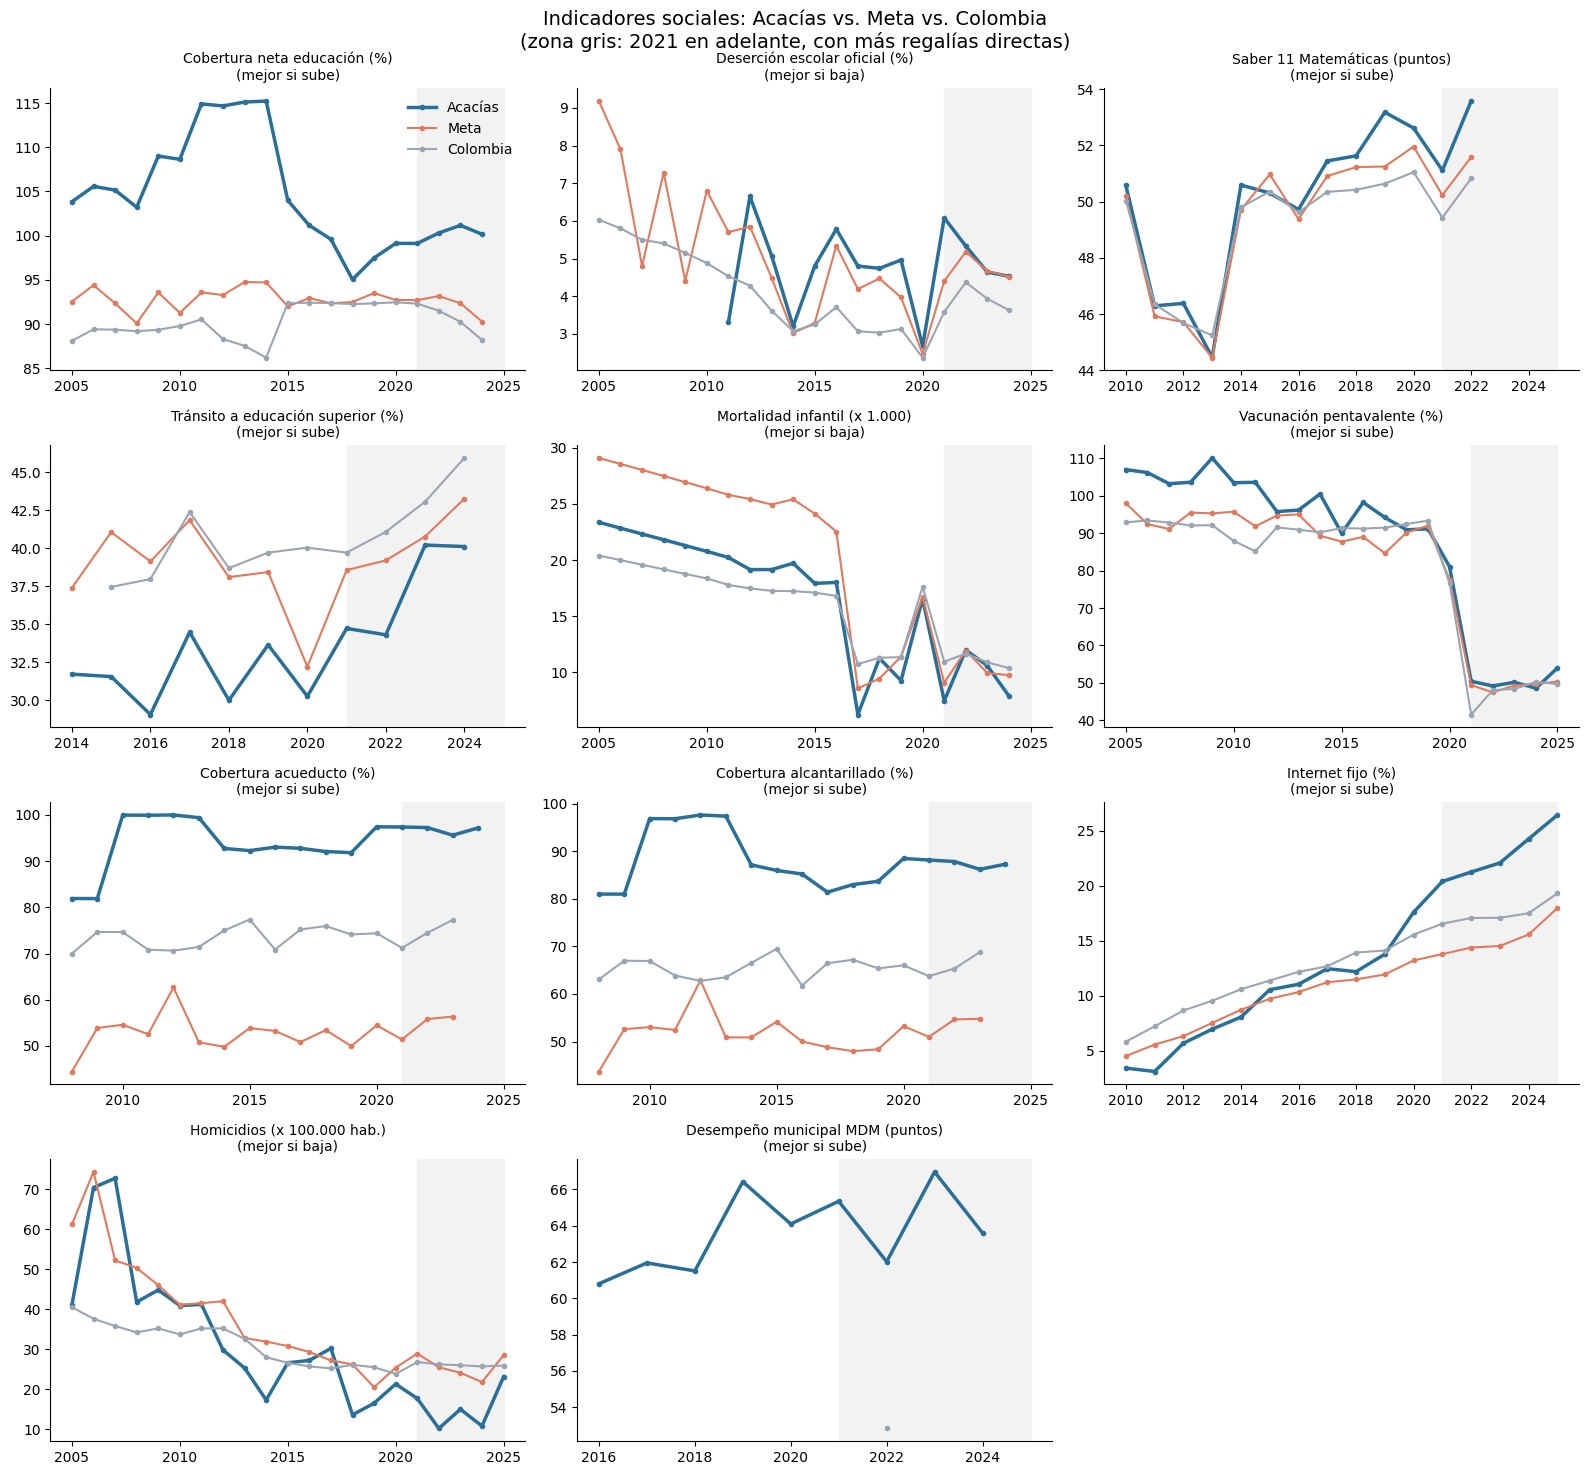

In [5]:
graficar = [n for n in INDICADORES["nombre"] if INDICADORES.set_index("nombre").loc[n, "mejor"] != ""]

fig, axes = plt.subplots(4, 3, figsize=(16, 15))
for ax, nombre in zip(axes.flat, graficar):
    sub = panel[(panel["nombre"] == nombre) & (panel["lugar"].isin(COLORES)) & (panel["anio"].between(2005, 2025))]
    for lugar, color in COLORES.items():
        serie = sub[sub["lugar"] == lugar].sort_values("anio")
        ax.plot(serie["anio"], serie["valor"], marker="o", ms=3, color=color, label=lugar,
                lw=2.5 if lugar == "Acacías" else 1.5)
    ax.axvspan(2021, 2025, color="#f2f2f2", zorder=0)
    mejor = INDICADORES.set_index("nombre").loc[nombre, "mejor"]
    ax.set_title(f"{nombre}\n(mejor si {mejor})", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.xaxis.get_major_locator().set_params(integer=True)
for ax in axes.flat[len(graficar):]:
    ax.axis("off")
axes.flat[0].legend(frameon=False)
fig.suptitle("Indicadores sociales: Acacías vs. Meta vs. Colombia\n(zona gris: 2021 en adelante, con más regalías directas)", fontsize=14)
plt.tight_layout()
plt.show()

**Lecturas:**
- Acacías **supera al Meta y a Colombia** en acueducto, alcantarillado, internet y Saber 11 de matemáticas, y tiene menos homicidios que el promedio.
- **Punto débil: el tránsito a la educación superior.** Solo 4 de cada 10 bachilleres entran directo a la universidad, por debajo del Meta y del país.
- En la zona gris (más regalías directas desde 2021) no se ve un cambio de tendencia evidente en la mayoría de indicadores.

## 5. Antes y después

Se compara el **primer año con datos desde 2011** con el **último disponible**. 2011 es un buen punto de partida: es el año anterior al Sistema General de Regalías actual.

In [6]:
def antes_despues(df, lugar, desde=2011):
    sub = df[(df["lugar"] == lugar) & (df["anio"] >= desde) & df["valor"].notna()].sort_values("anio")
    g = sub.groupby("nombre")
    tabla = pd.DataFrame({
        "anio_inicial": g["anio"].first(), "valor_inicial": g["valor"].first(),
        "anio_final": g["anio"].last(), "valor_final": g["valor"].last(),
    })
    tabla["cambio"] = tabla["valor_final"] - tabla["valor_inicial"]
    mejor = INDICADORES.set_index("nombre")["mejor"]
    tabla["mejoró"] = [
        "" if mejor[n] == "" else ("✅" if (c > 0) == (mejor[n] == "sube") and c != 0 else "❌")
        for n, c in zip(tabla.index, tabla["cambio"])
    ]
    return tabla.loc[[n for n in INDICADORES["nombre"] if n in tabla.index]]

ad_acacias = antes_despues(panel, "Acacías")
ad_acacias

,anio_inicial,valor_inicial,anio_final,valor_final,cambio,mejoró
nombre,,,,,,
Cobertura neta educación (%),2011,114.9,2024,100.2,-14.7,❌
Deserción escolar oficial (%),2011,3.3,2024,4.5,1.2,❌
Saber 11 Matemáticas (puntos),2011,46.3,2022,53.6,7.3,✅
Tránsito a educación superior (%),2014,31.7,2024,40.1,8.4,✅
Mortalidad infantil (x 1.000),2011,20.2,2024,7.9,-12.4,✅
Vacunación pentavalente (%),2011,103.6,2025,54.0,-49.7,❌
Cobertura acueducto (%),2011,99.9,2024,97.2,-2.7,❌
Cobertura alcantarillado (%),2011,96.8,2024,87.2,-9.5,❌
Internet fijo (%),2011,3.1,2025,26.4,23.3,✅


## 6. Comparación con otros municipios petroleros

Último año disponible de cada indicador.

In [7]:
ultimo = (panel[panel["valor"].notna() & (panel["anio"] <= 2025)]
            .sort_values("anio").groupby(["nombre", "lugar"]).last().reset_index())
comparacion = ultimo.pivot(index="nombre", columns="lugar", values="valor")[list(ENTIDADES.values())]
comparacion = comparacion.loc[[n for n in INDICADORES["nombre"] if n in comparacion.index]]
# Los indicadores de finanzas de Meta y Colombia no son comparables con los de un municipio
comparacion.loc[["Regalías giradas per cápita ($)", "Ingresos por transferencias (%)"], ["Meta", "Colombia"]] = None
comparacion

lugar,Acacías,Meta,Colombia,Castilla La Nueva,Guamal,Puerto Gaitán,Villavicencio
nombre,,,,,,,
Cobertura neta educación (%),100.2,90.3,88.2,85.8,114.1,126.7,87.6
Deserción escolar oficial (%),4.5,4.5,3.6,4.6,5.9,4.0,4.1
Saber 11 Matemáticas (puntos),53.6,51.6,50.8,50.2,50.7,45.0,53.2
Tránsito a educación superior (%),40.1,43.3,45.9,30.9,38.8,27.3,49.4
Mortalidad infantil (x 1.000),7.9,9.7,10.4,13.2,6.8,22.2,8.3
Vacunación pentavalente (%),54.0,50.3,49.7,52.6,53.4,45.8,49.8
Cobertura acueducto (%),97.2,56.4,77.3,85.0,82.2,21.5,51.5
Cobertura alcantarillado (%),87.2,54.8,68.8,85.0,56.8,21.6,53.1
Internet fijo (%),26.4,18.0,19.3,6.8,11.2,15.7,23.5


## 7. Dependencia del petróleo

Dos indicadores de economía muestran qué tanto depende Acacías del petróleo:
- **Peso de las actividades primarias** (minería e hidrocarburos, agro) en el valor agregado del municipio.
- **Valor agregado per cápita** frente al promedio nacional. Un valor de 400% quiere decir que se produce 4 veces más riqueza por habitante que el promedio del país.

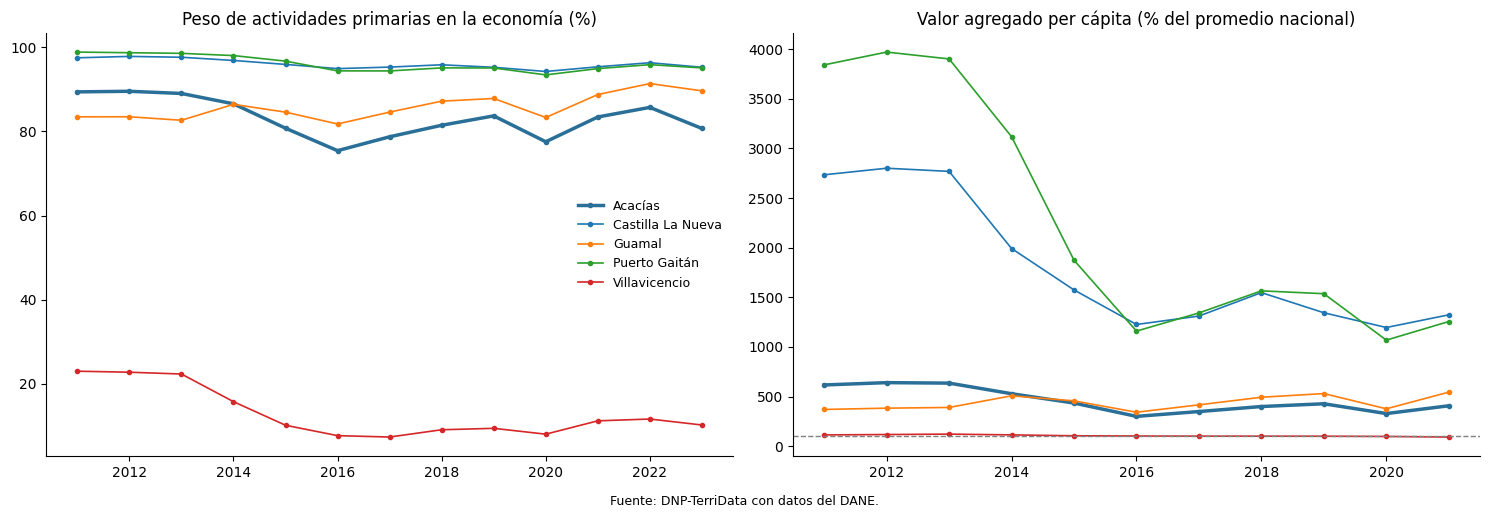

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
petroleros = ["Acacías", "Castilla La Nueva", "Guamal", "Puerto Gaitán", "Villavicencio"]
for a, nombre in zip(ax, ["Peso de actividades primarias en la economía (%)",
                          "Valor agregado per cápita (% del promedio nacional)"]):
    sub = panel[panel["nombre"] == nombre]
    for lugar in petroleros:
        s = sub[sub["lugar"] == lugar].sort_values("anio")
        a.plot(s["anio"], s["valor"], marker="o", ms=3, label=lugar,
               lw=2.5 if lugar == "Acacías" else 1.2, color="#2a6f97" if lugar == "Acacías" else None)
    a.set_title(nombre)
    a.spines[["top", "right"]].set_visible(False)
ax[1].axhline(100, color="gray", ls="--", lw=1)
ax[0].legend(frameon=False, fontsize=9)
fig.text(0.5, -0.02, "Fuente: DNP-TerriData con datos del DANE.", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

## 8. Pobreza: censos 2005 vs. 2018

El índice de pobreza multidimensional (IPM) y las necesidades básicas insatisfechas (NBI) por municipio **solo se miden con los censos**. Por eso hay dos puntos: 2005 y 2018.

In [9]:
POBREZA = ["indice de pobreza multidimensional - IPM (Censo)", "IPM - Centros poblados y rural disperso (Censo)",
           "indice de Necesidades Basicas Insatisfechas - NBI", "Poblacion en condicion de miseria"]
censo = (td[td["indicador"].isin(POBREZA) & td["cod_entidad"].isin(ENTIDADES)]
           .assign(lugar=lambda d: d["cod_entidad"].map(ENTIDADES))
           .pivot_table(index=["indicador", "lugar"], columns="anio", values="valor"))
censo["cambio_pts"] = censo[2018] - censo[2005]
censo

anio                                                                 2005  2018  cambio_pts
indicador                                         lugar                                    
IPM - Centros poblados y rural disperso (Censo)   Acacías            70.8  29.8       -41.0
                                                  Castilla La Nueva  63.6  27.5       -36.1
                                                  Colombia           80.1   NaN         NaN
                                                  Guamal             56.7  29.9       -26.8
                                                  Meta               75.0   NaN         NaN
                                                  Puerto Gaitán      95.5  71.6       -23.9
                                                  Villavicencio      61.9  26.7       -35.2
Poblacion en condicion de miseria                 Acacías             5.6   0.6        -5.0
                                                  Castilla La Nueva   4.9   1.2        -3.6
                                                  Colombia           10.6   3.8        -6.8
                                                  Guamal              3.6   1.1        -2.5
                                                  Meta                8.1   3.6        -4.4
                                                  Puerto Gaitán      44.4  25.8       -18.6
                                                  Villavicencio       4.2   0.8        -3.4
indice de Necesidades Basicas Insatisfechas - NBI Acacías            22.7   6.3       -16.3
                                                  Castilla La Nueva  23.4   9.9       -13.6
                                                  Colombia           27.8  14.3       -13.5
                                                  Guamal             19.4   8.7       -10.7
                                                  Meta               25.0  13.4       -11.6
                                                  Puerto Gaitán      65.5  44.8       -20.6
                                                  Villavicencio      17.1   6.4       -10.7
indice de pobreza multidimensional - IPM (Censo)  Acacías            48.5  19.2       -29.3
                                                  Castilla La Nueva  53.5  23.1       -30.4
                                                  Colombia           49.0  25.6       -23.3
                                                  Guamal             45.9  22.6       -23.3
                                                  Meta               51.1  25.2       -25.9
                                                  Puerto Gaitán      80.5  51.8       -28.7
                                                  Villavicencio      40.9  15.9       -25.0

## 9. Población y regalías por habitante

La población municipal viene en las proyecciones del DANE (desde 2018) como hombres + mujeres. Con ella se calculan las **Asignaciones Directas recibidas por habitante**, en pesos de 2025, usando la salida del notebook 03.

In [10]:
pob = (td[(td["cod_entidad"] == "50006") &
          td["indicador"].isin(["Población total de hombres", "Población total de mujeres"])]
         .groupby("anio")["valor"].sum().rename("poblacion"))

gvr = pd.read_csv(OUT / "acacias_generado_vs_recibido.csv").set_index("anio")
per_capita = gvr[[f"asignaciones_directas_recibidas_const{ANIO_BASE}", f"regalias_generadas_anh_const{ANIO_BASE}"]].join(pob, how="inner")
per_capita["recibidas_por_habitante"] = per_capita[f"asignaciones_directas_recibidas_const{ANIO_BASE}"] / per_capita["poblacion"]
per_capita["generadas_por_habitante"] = per_capita[f"regalias_generadas_anh_const{ANIO_BASE}"] / per_capita["poblacion"]
per_capita.loc[2018:2025, ["poblacion", "recibidas_por_habitante", "generadas_por_habitante"]]

,poblacion,recibidas_por_habitante,generadas_por_habitante
anio,,,
2018,"88,028.0","202,619.5","7,822,001.2"
2019,"90,779.0","173,140.2","7,951,101.0"
2020,"93,760.0","79,498.4","3,108,950.4"
2021,"96,064.0","656,741.0","8,622,367.8"
2022,"98,080.0","680,860.1","12,372,488.1"
2023,"100,048.0","678,186.4","7,508,183.3"
2024,"102,025.0","563,422.4","6,282,294.0"
2025,"103,943.0","457,196.8","6,261,465.4"


**Lectura:** cada habitante de Acacías "genera" con el petróleo varios millones de pesos al año en regalías, pero la alcaldía recibe en Asignaciones Directas solo unos cientos de miles de pesos por habitante.

## 10. Exportar

In [11]:
td[td["cod_entidad"].isin(ENTIDADES)].to_csv(OUT / "terridata_limpio_comparables.csv", index=False, encoding="utf-8-sig")
panel.to_csv(OUT / "terridata_panel_indicadores.csv", index=False, encoding="utf-8-sig")
ad_acacias.to_csv(OUT / "terridata_acacias_antes_despues.csv", encoding="utf-8-sig")
comparacion.to_csv(OUT / "terridata_comparacion_petroleros.csv", encoding="utf-8-sig")
censo.to_csv(OUT / "terridata_pobreza_censos.csv", encoding="utf-8-sig")
per_capita.to_csv(OUT / "acacias_regalias_per_capita.csv", encoding="utf-8-sig")
print("Listo:", sorted(p.name for p in OUT.glob("terridata_*.csv")) + ["acacias_regalias_per_capita.csv"])

Listo: ['terridata_acacias_antes_despues.csv', 'terridata_comparacion_petroleros.csv', 'terridata_limpio_comparables.csv', 'terridata_meta_colombia.csv', 'terridata_panel_indicadores.csv', 'terridata_pobreza_censos.csv', 'acacias_regalias_per_capita.csv']


## Notas para el análisis

- **Correlación no es causalidad.** Que un indicador mejore mientras llegan regalías no prueba que las regalías lo causaron. Para afirmar algo más fuerte hay que comparar con municipios parecidos que no reciben regalías.
- **Regalías per cápita de TerriData** ("valor efectivamente girado") incluye más conceptos que las Asignaciones Directas de SICODIS, por eso los valores no coinciden exactamente.
- Revisar los indicadores con saltos raros (vacunación desde 2021, acueducto rural en 2014) antes de sacar conclusiones con ellos.